In [1]:
# Журнал 
LOG_COLS = ["field", "issue", "scope", "n_rows", "value_before", "action", "value_after", "rationale"]
cleaning_log = []

def add_log(field, issue, scope, n_rows, value_before, action, value_after, rationale):
    cleaning_log.append(dict(zip(LOG_COLS, [field, issue, scope, n_rows, value_before, action, value_after, rationale])))


## 0. Зачитаем данные 

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np

RAW_PATH = Path("..") / "data" / "raw" / "rent_v28.csv"
print(RAW_PATH.resolve(), "| файл найден:", RAW_PATH.exists())

df_naive = pd.read_csv(RAW_PATH, sep=";", encoding="cp1251", dtype={"id": "string"})

print(f"Размер: {df_naive.shape[0]} строк × {df_naive.shape[1]} столбцов")
df_naive.head(3)

C:\Users\6anna\PycharmProjects\Suhodolova_Anna_Lab2\data\raw\rent_v28.csv | файл найден: True
Размер: 12360 строк × 1 столбцов


,listing_id|publication_date|district|house_type|year_built|floors_total|floor|elevator|rooms|total_area|living_area|kitchen_area|ceiling_height|renovation|furniture|appliances|balcony|parking|metro_distance_m|distance_to_center_km|pets_allowed|seller_type|photos_count|response_time_hours|max_tenants|rent_rub
0,05d19173|2026-09-12|Первомайский|панельный|197...
1,1bcee754|2026-10-12|Центральный|кирпичный|1964...
2,9872d60f|2026-09-22|Заречный|панельный|1984|10...


Вывод: кодировку необходимо использовать "cp1251", а разделителями являются |
## 1. Минимальная подготовка данных до отделения test
### 1.1 Чтение данных с корректными типами

In [3]:
STR_COLS = ["listing_id"]
DATE_COLS = ["publication_date"]
CAT_COLS = ["district", "house_type", "elevator", "renovation", "furniture", "appliances", "balcony", "parking", "pets_allowed", "seller_type"]
INT_COLS = ["year_built", "floors_total", "floor", "rooms", "metro_distance_m", "photos_count", "max_tenants", "rent_rub"]
FLOAT_COLS = ["total_area", "living_area", "kitchen_area", "ceiling_height", "distance_to_center_km", "response_time_hours"]

df_raw = pd.read_csv(RAW_PATH, sep="|", encoding="cp1251", dtype=str, keep_default_na=False, na_values=[""])

def to_num(s):
    clean = s.str.replace(r"[\s]", "", regex=True).str.replace(",", ".", regex=False)
    return pd.to_numeric(clean, errors="coerce")

df = df_raw.copy()
df[STR_COLS] = df[STR_COLS].astype("string")
df[CAT_COLS] = df[CAT_COLS].astype("category")
df[DATE_COLS[0]] = pd.to_datetime(df_raw[DATE_COLS[0]], errors="coerce")

for c in INT_COLS + FLOAT_COLS:
    df[c] = to_num(df_raw[c])
    bad = df_raw[c].notna() & df[c].isna()
    if bad.any():
        print(f"{c}: не приведено {bad.sum()} знач., примеры: {df_raw.loc[bad, c].unique()[:5]}")
    if c in INT_COLS:
        if (df[c].dropna() % 1 == 0).all():
            df[c] = df[c].astype("Int64")
        else:
            print(f"{c}: есть дробные значения, оставлен float64")

bad_dates = df_raw[DATE_COLS[0]].notna() & df[DATE_COLS[0]].isna()
print(f"{DATE_COLS[0]}: не приведено {bad_dates.sum()}, примеры: {df_raw.loc[bad_dates, DATE_COLS[0]].unique()[:5]}")

print(f"Размер: {df.shape[0]} строк × {df.shape[1]} столбцов")
df.head(3)


add_log("rent_v28*", "чтение и приведение типов", "вся выгрузка", len(df_raw), f"{RAW_PATH.name}: текст, sep='|', cp1251", "read_csv как текст, затем приведение типов", f"{df.shape[0]} строк × {df.shape[1]} столбцов", "числа записаны с пробелами и запятой, поэтому типы заданы после чтения")
pd.DataFrame(cleaning_log, columns=LOG_COLS)

publication_date: не приведено 0, примеры: []
Размер: 12360 строк × 26 столбцов


,field,issue,scope,n_rows,value_before,action,value_after,rationale
0,rent_v28*,чтение и приведение типов,вся выгрузка,12360,"rent_v28.csv: текст, sep='|', cp1251","read_csv как текст, затем приведение типов",12360 строк × 26 столбцов,"числа записаны с пробелами и запятой, поэтому ..."


### 1.2 Проверка и удаление полных дубликатов 

In [4]:
dup_mask = df.duplicated(keep="first")
print("Полных дубликатов (без первого экземпляра):", dup_mask.sum())
display(df[df.duplicated(keep=False)].sort_values(list(df.columns)).head(10))

n_before = len(df)
df = df[~dup_mask]
add_log("rent_v28*", "полные дубликаты строк", "вся выгрузка", int(dup_mask.sum()), f"{n_before} строк", "удалены, оставлен первый экземпляр", f"{len(df)} строк", "копия строки могла бы попасть и в train, и в test")
print(f"Строк: {n_before} -> {len(df)}")
      
add_log("rent_v28*", "полные дубликаты строк", "вся выгрузка", int(dup_mask.sum()), f"{n_before} строк", "удалены, оставлен первый экземпляр", f"{len(df)} строк", "копия строки могла бы попасть и в train, и в test")

Полных дубликатов (без первого экземпляра): 180


,listing_id,publication_date,district,house_type,year_built,floors_total,floor,elevator,rooms,total_area,...,balcony,parking,metro_distance_m,distance_to_center_km,pets_allowed,seller_type,photos_count,response_time_hours,max_tenants,rent_rub
4614,02069026,2026-09-30,Ленинский,панельный,2011,25,3,да,2,47.5,...,2,нет,640,5.4,нет,собственник,9,0.7,4,40000
6031,02069026,2026-09-30,Ленинский,панельный,2011,25,3,да,2,47.5,...,2,нет,640,5.4,нет,собственник,9,0.7,4,40000
9840,027eccde,2026-09-28,Первомайский,панельный,1964,5,1,нет,3,50.8,...,1,нет,430,9.9,нет,собственник,5,9.1,5,20000
11421,027eccde,2026-09-28,Первомайский,панельный,1964,5,1,нет,3,50.8,...,1,нет,430,9.9,нет,собственник,5,9.1,5,20000
3450,02ef7f84,2026-09-20,Ленинский,панельный,1961,5,3,нет,3,50.6,...,1,нет,1690,6.6,нет,собственник,4,0.9,3,20500
4299,02ef7f84,2026-09-20,Ленинский,панельный,1961,5,3,нет,3,50.6,...,1,нет,1690,6.6,нет,собственник,4,0.9,3,20500
3731,046dd6f1,2026-10-04,Железнодорожный,монолитный,2025,9,1,да,0,21.5,...,1,нет,1160,7.3,нет,агентство,7,2.6,1,9000
5082,046dd6f1,2026-10-04,Железнодорожный,монолитный,2025,9,1,да,0,21.5,...,1,нет,1160,7.3,нет,агентство,7,2.6,1,9000
2836,0577a812,2026-09-24,Центральный,блочный,2005,10,7,да,4,100.9,...,1,нет,680,2.5,да,агентство,10,4.6,4,97000
3964,0577a812,2026-09-24,Центральный,блочный,2005,10,7,да,4,100.9,...,1,нет,680,2.5,да,агентство,10,4.6,4,97000


Строк: 12360 -> 12180


### 1.3 Удаляем строки без целевой переменной

In [5]:
empty_target = df["rent_rub"].isna()
print("Пустой rent_rub:", empty_target.sum())
display(df.loc[empty_target, ["listing_id", "rent_rub"]].head(10))

n_before = len(df)
df = df[~empty_target]
add_log("rent_rub", "пустое значение целевой переменной", "вся выгрузка", int(empty_target.sum()), f"{n_before} строк", "строки удалены", f"{len(df)} строк", "без цели нельзя ни обучить модель, ни посчитать метрики")
print(f"Строк: {n_before} -> {len(df)}")

Пустой rent_rub: 37


,listing_id,rent_rub
919,3fa182c8,<NA>
1496,f6590259,<NA>
1543,53c61df1,<NA>
1547,a38af5bd,<NA>
1927,4bf52500,<NA>
2495,59f93762,<NA>
3419,85217485,<NA>
3957,4fb33866,<NA>
4020,89551ae6,<NA>
4905,4471deb1,<NA>


Строк: 12180 -> 12143


Вывод: удалили все дубликаты и строки в которых не указана целевая переменная, теперь эти данные можно зарбивать на train, valid и est

## 2. Деление данных на test, validation и train
При разбиении выделим 15% на тест и 15% на валидацию, остальные 70% - train 

In [6]:
from sklearn.model_selection import train_test_split

# Задаём параметры разбиения (по 15% на валиданию и тест)
RANDOM_STATE = 42
TEST_SIZE, VALID_SIZE = 0.15, 0.15
INTERIM_PATH = Path("..") / "data" / "interim" / "test.csv"

# Разбиваем целевую переменную на 10 квантилей для стратификации
price_bins = pd.qcut(df["rent_rub"].astype(float), q=10, duplicates="drop")
# отделяем тестовую выборку (15%) от остальной части данных  с сохранением распределения цен
dev_idx, test_idx = train_test_split(df.index, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=price_bins)
# делим оставшиеся 85% на train и valid
train_idx, valid_idx = train_test_split(dev_idx, test_size=VALID_SIZE / (1 - TEST_SIZE), random_state=RANDOM_STATE, stratify=price_bins.loc[dev_idx])

# Сохраняем выбранные строки в тест в изначальном виде в отдельном файле
raw = pd.read_csv(RAW_PATH, sep="|", encoding="cp1251", dtype=str, keep_default_na=False, na_values=[""])
INTERIM_PATH.parent.mkdir(parents=True, exist_ok=True)
raw.loc[test_idx.sort_values()].to_csv(INTERIM_PATH, sep="|", encoding="cp1251", index=False)

# Формируем итоговые датафреймы train, valid и test по полученным индексам
df_train, df_valid, df_test = df.loc[train_idx], df.loc[valid_idx], df.loc[test_idx]

# Выводим диагностику
test_check = pd.read_csv(INTERIM_PATH, sep="|", encoding="cp1251", dtype=str, keep_default_na=False, na_values=[""])
print(f"train {len(df_train)} | valid {len(df_valid)} | test {len(df_test)}")
print("Пересечений:", len(set(train_idx) & set(test_idx)), len(set(valid_idx) & set(test_idx)), len(set(train_idx) & set(valid_idx)))
print("Тест сохранён:", test_check.shape)

add_log("rent_v28*", "разбиение на выборки", "вся выгрузка", len(df), f"{len(df)} строк", f"train/valid/test, стратификация по децилям rent_rub, RANDOM_STATE={RANDOM_STATE}", f"{len(df_train)}/{len(df_valid)}/{len(df_test)}", "тест сохранён сырым в data/interim/, обучаемые параметры считаются только по train")

train 8499 | valid 1822 | test 1822
Пересечений: 0 0 0
Тест сохранён: (1822, 26)


,field,issue,scope,n_rows,value_before,action,value_after,rationale
0,rent_v28*,чтение и приведение типов,вся выгрузка,12360,"rent_v28.csv: текст, sep='|', cp1251","read_csv как текст, затем приведение типов",12360 строк × 26 столбцов,"числа записаны с пробелами и запятой, поэтому ..."
1,rent_v28*,полные дубликаты строк,вся выгрузка,180,12360 строк,"удалены, оставлен первый экземпляр",12180 строк,"копия строки могла бы попасть и в train, и в test"
2,rent_v28*,полные дубликаты строк,вся выгрузка,180,12360 строк,"удалены, оставлен первый экземпляр",12180 строк,"копия строки могла бы попасть и в train, и в test"
3,rent_rub,пустое значение целевой переменной,вся выгрузка,37,12180 строк,строки удалены,12143 строк,"без цели нельзя ни обучить модель, ни посчитат..."
4,rent_v28*,разбиение на выборки,вся выгрузка,12143,12143 строк,"train/valid/test, стратификация по децилям ren...",8499/1822/1822,"тест сохранён сырым в data/interim/, обучаемые..."


,столбец,выборка,медиана train,медиана,KS,p,"пропуски train, %","пропуски, %"
3,floors_total,test,10.00,9.00,0.045,0.004,0.00,0.00
9,metro_distance_m,test,1310.00,1230.00,0.035,0.052,0.00,0.00
17,total_area,test,47.30,46.40,0.034,0.065,0.00,0.00
25,distance_to_center_km,test,7.10,6.90,0.031,0.108,0.00,0.00
24,distance_to_center_km,valid,7.10,6.90,0.029,0.152,0.00,0.00
20,kitchen_area,valid,8.50,8.40,0.029,0.175,7.24,7.52
1,year_built,test,1985.00,1985.00,0.027,0.254,9.52,10.04
19,living_area,test,26.40,26.00,0.025,0.335,6.00,5.49
23,ceiling_height,test,2.67,2.66,0.024,0.395,5.18,5.10
8,metro_distance_m,valid,1310.00,1240.00,0.024,0.327,0.00,0.00


,столбец,выборка,"макс. разница долей, п.п.",значение
13,balcony,test,3.35,1
3,house_type,test,2.41,монолитный
11,appliances,test,2.29,да
5,elevator,test,1.99,да
1,district,test,1.89,Заречный
19,seller_type,test,1.80,собственник
0,district,valid,1.62,Октябрьский
15,parking,test,1.60,нет
18,seller_type,valid,1.54,собственник
14,parking,valid,1.49,подземная


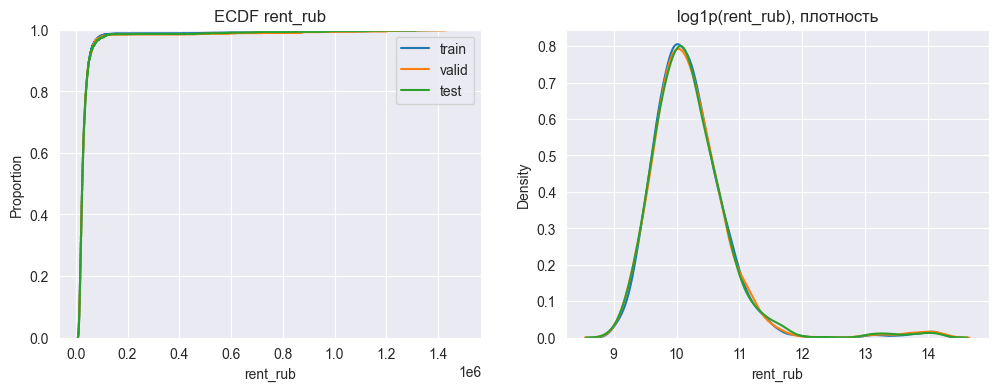

In [9]:
from scipy import stats
import seaborn as sns
import matplotlib.pyplot as plt

# Сравниваем valid и test с train
parts = {"valid": df_valid, "test": df_test}

# Числовые признаки: сравниваем центр (медиану) и долю пропусков. (KS — максимальное расстояние между двумя ECDF(ЭФР) (долями наблюдений ≤ порога))
rows = []
for c in INT_COLS + FLOAT_COLS:
    a = df_train[c].dropna().astype(float)
    for name, part in parts.items():
        b = part[c].dropna().astype(float)
        ks = stats.ks_2samp(a, b)
        rows.append({"столбец": c, "выборка": name, "медиана train": a.median(), "медиана": b.median(), "KS": round(ks.statistic, 3), "p": round(ks.pvalue, 3), "пропуски train, %": round(df_train[c].isna().mean() * 100, 2), "пропуски, %": round(part[c].isna().mean() * 100, 2)})
num_cmp = pd.DataFrame(rows)
display(num_cmp.sort_values("KS", ascending=False).head(15))

# Категориальные признаки: сравниваем частоты и доли. Пропуск считаем отдельной категорией "<NaN>".
rows = []
for c in CAT_COLS:
    p_tr = df_train[c].astype("string").fillna("<NaN>").value_counts(normalize=True)
    for name, part in parts.items():
        p = part[c].astype("string").fillna("<NaN>").value_counts(normalize=True)
        diff = p_tr.sub(p, fill_value=0).abs() * 100
        rows.append({"столбец": c, "выборка": name, "макс. разница долей, п.п.": round(diff.max(), 2), "значение": diff.idxmax()})
display(pd.DataFrame(rows).sort_values("макс. разница долей, п.п.", ascending=False))

# Целевая переменная: ECDF(ЭФР) показывает долю объявлений с ценой ≤ порога и ничего не сглаживает.
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, part in {"train": df_train, "valid": df_valid, "test": df_test}.items():
    sns.ecdfplot(part["rent_rub"].astype(float), ax=ax[0], label=name)
    sns.kdeplot(np.log1p(part["rent_rub"].astype(float)), ax=ax[1], label=name)
ax[0].set_title("ECDF rent_rub"); ax[1].set_title("log1p(rent_rub), плотность")
ax[0].legend()
plt.show()

Вывод: распределение целевой переменной на всех трёх кусках данных совпадает.

In [8]:
passport = pd.DataFrame({
    "тип": df.dtypes.astype(str),
    "пропусков": df.isna().sum(),
    "доля пропусков, %": (df.isna().mean() * 100).round(2),
    "уникальных": df.nunique(dropna=True),
})
display(passport)

print("\nКатегориальные столбцы: сколько раз встречается каждое значение")
for col in CAT_COLS:
    vc = df[col].value_counts(dropna=False)
    print(f"\n{col} (категорий: {df[col].nunique()}):")
    display(vc.to_frame("количество").assign(доля=lambda t: (t["количество"] / len(df) * 100).round(2)))

,тип,пропусков,"доля пропусков, %",уникальных
listing_id,string,0,0.00,12143
publication_date,datetime64[ns],0,0.00,61
district,category,55,0.45,12
house_type,category,0,0.00,5
year_built,Int64,1150,9.47,106
floors_total,Int64,0,0.00,26
floor,Int64,0,0.00,27
elevator,category,0,0.00,2
rooms,Int64,0,0.00,6
total_area,float64,0,0.00,1068



Категориальные столбцы: сколько раз встречается каждое значение

district (категорий: 12):


,количество,доля
district,,
Советский,1281,10.55
Ленинский,1191,9.81
Кировский,1147,9.45
Заречный,1134,9.34
Первомайский,1077,8.87
Октябрьский,978,8.05
Северный,961,7.91
Железнодорожный,917,7.55
Центральный,902,7.43



house_type (категорий: 5):


,количество,доля
house_type,,
панельный,5433,44.74
кирпичный,3431,28.25
монолитный,2490,20.51
блочный,720,5.93
деревянный,69,0.57



elevator (категорий: 2):


... (11 outputs left out)


pets_allowed (категорий: 2):


,количество,доля
pets_allowed,,
нет,7926,65.27
да,4217,34.73



seller_type (категорий: 2):


,количество,доля
seller_type,,
собственник,7310,60.2
агентство,4833,39.8
